# Exploratory Data Analysis (EDA): O-Level Students' Mathematics Score Prediction
Explores raw student data (`../data/student_data.csv`) to inspect dimensions, audit cleaning steps, examine time/categorical distributions, check statistical relationships (ANOVA, VIF, correlations, outliers), and export clean datasets for modeling.

In [31]:
import os, warnings
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid", palette="muted")
pd.set_option("display.max_columns", None)
os.makedirs("../artifacts/eda_outputs", exist_ok=True)

def plot_annotated_countplot(df: pd.DataFrame, column: str, title: str) -> None:
    plt.figure(figsize=(8, 4))
    # Convert NaN values to a string label for plotting so matplotlib doesn't fail on float NaN
    plot_series = df[column].fillna("Missing (NaN)").astype(str)
    order = plot_series.value_counts().index
    
    ax = sns.countplot(x=plot_series, order=order)
    ax.set_title(title, fontsize=12, fontweight="bold")
    ax.set_xlabel(column)
    
    for patch in ax.patches:
        h = patch.get_height()
        if not np.isnan(h):
            ax.annotate(
                f"{int(h)}",
                (patch.get_x() + patch.get_width() / 2.0, h),
                ha="center",
                va="center",
                xytext=(0, 8),
                textcoords="offset points",
            )
    plt.tight_layout()
    plt.show()



## 1. Dataset Loading & Schema Overview

In this section, we load the raw student dataset (`../data/student_data.csv`) and inspect:
1. **Dimensions:** Total number of rows and columns.
2. **Schema & Data Types:** Numeric versus categorical/string features.
3. **Missing Values & Cardinality:** Null counts, percentages, and unique value counts per column to flag immediate data quality issues.


In [32]:
df=pd.read_csv('C:/Users/Ram/Desktop/AIAP Foundation/Bonus regression/bonus regression/data/student_data.csv')

print(f"Dataset Dimensions: {df.shape[0]:,} rows x {df.shape[1]} columns\n")

schema_summary = pd.DataFrame({
    "Data Type": df.dtypes,
    "Non-Null Count": df.notnull().sum(),
    "Null Count": df.isnull().sum(),
    "Null (%)": (df.isnull().mean() * 100).round(2),
    "Unique Values": df.nunique(dropna=True),
})

display(schema_summary)
print("\nDescriptive Statistics (Numerical Features):")
display(df.describe().T)


Dataset Dimensions: 15,900 rows x 18 columns



,Data Type,Non-Null Count,Null Count,Null (%),Unique Values
index,int64,15900,0,0.00,15900
number_of_siblings,int64,15900,0,0.00,3
direct_admission,str,15900,0,0.00,2
CCA,str,12071,3829,24.08,7
learning_style,str,15900,0,0.00,2
student_id,str,15900,0,0.00,15000
gender,str,15900,0,0.00,2
tuition,str,15900,0,0.00,4
final_test,float64,15405,495,3.11,68
n_male,int64,15900,0,0.00,32



Descriptive Statistics (Numerical Features):


,count,mean,std,min,25%,50%,75%,max
index,15900.0,7949.500000,4590.078975,0.0,3974.75,7949.5,11924.25,15899.0
number_of_siblings,15900.0,0.886541,0.751346,0.0,0.00,1.0,1.00,2.0
final_test,15405.0,67.165401,13.977879,32.0,56.00,68.0,78.00,100.0
n_male,15900.0,13.880000,6.552584,0.0,10.00,14.0,18.00,31.0
n_female,15900.0,8.906038,6.663852,0.0,4.00,8.0,13.00,31.0
age,15900.0,15.213459,1.758941,-5.0,15.00,15.0,16.00,16.0
hours_per_week,15900.0,10.312579,4.461861,0.0,7.00,9.0,14.00,20.0
attendance_rate,15122.0,93.270268,7.984230,40.0,92.00,95.0,97.00,100.0


## 2. Duplicate & Missing Value Audit

**Findings & Decisions:**
* **Duplicate Records:** Repeated `student_id` entries represent duplicate student records rather than distinct observations. We drop duplicates while keeping the first occurrence and log the exact row count removed.
* **Missing Target (`final_test`):** Rows without a target score cannot be used for supervised training or evaluation, so they are removed rather than imputed.
* **Missing Attendance (`attendance_rate`):** Because attendance is a primary behavioral predictor and cannot be reliably guessed without risking label leakage or distortion, rows with missing `attendance_rate` are dropped.


In [33]:
initial_rows = len(df)

# 1. Remove duplicate student_id rows
dup_count = df.duplicated(subset=["student_id"]).sum()
df = df.drop_duplicates(subset=["student_id"], keep="first").copy()
print(f"Duplicates based on 'student_id' dropped: {dup_count} rows (Remaining: {len(df):,})")

# 2. Drop rows missing target or critical attendance_rate
missing_target = df["final_test"].isnull().sum()
missing_attendance = df["attendance_rate"].isnull().sum()
df = df.dropna(subset=["final_test", "attendance_rate"]).copy()



print(f"Missing 'final_test' before drop: {missing_target} | Missing 'attendance_rate' before drop: {missing_attendance}")
print(f"Total rows dropped in Step 2: {initial_rows - len(df):,} (Remaining shape: {df.shape})")


Duplicates based on 'student_id' dropped: 900 rows (Remaining: 15,000)
Missing 'final_test' before drop: 463 | Missing 'attendance_rate' before drop: 734
Total rows dropped in Step 2: 2,076 (Remaining shape: (13824, 18))


## 3. Categorical Profiling, Standardization & Binary Encoding

**Findings & Decisions:**
* **`CCA` Standardization:** Raw values contain inconsistent casing (`'ARTS'`, `'SPORTS'`, `'CLUBS'`) and missing representations (`'None'`, `'NONE'`, `NaN`). Rather than dropping ~3,959 records, missing/none entries are explicitly grouped into `'No_CCA'` so the model captures non-participation as a distinct category.
* **`tuition` Normalization & Encoding Fix:** Raw values mix `'Yes'`/`'No'` with shorthand `'Y'`/`'N'`. We standardize shorthand labels first, then apply `.str.strip().str.lower().map({'yes': 1, 'no': 0})` so lowercase strings match dictionary keys cleanly without creating `NaN` values.
* **Binary Features (`gender`, `direct_admission`):** Mapped cleanly to `1` and `0` for linear and tree-based modeling.


=== BEFORE CATEGORICAL CLEANING ===

CCA value counts:
CCA
Clubs     3403
Sports    3359
NaN       3309
Arts      3303
CLUBS      126
ARTS       113
NONE       113
SPORTS      98
Name: count, dtype: int64

tuition value counts:
tuition
Yes    7550
No     5765
Y       285
N       224
Name: count, dtype: int64

gender value counts:
gender
Male      6917
Female    6907
Name: count, dtype: int64

direct_admission value counts:
direct_admission
No     9798
Yes    4026
Name: count, dtype: int64


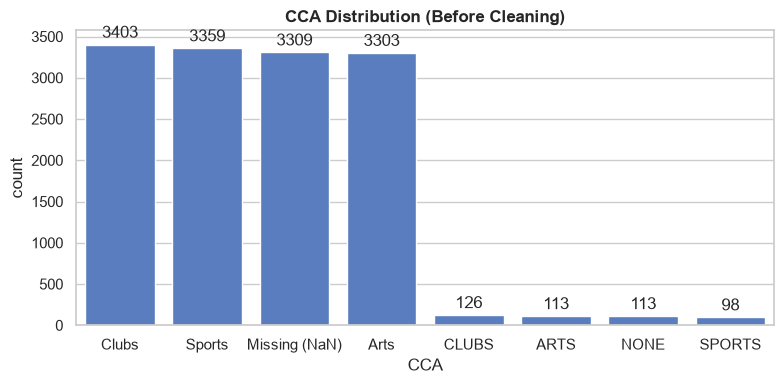


=== AFTER CATEGORICAL CLEANING & ENCODING ===

CCA value counts (Nulls: 0):
CCA
Clubs     3529
Sports    3457
No_CCA    3422
Arts      3416
Name: count, dtype: int64

tuition value counts (Nulls: 0):
tuition
1    7835
0    5989
Name: count, dtype: int64

gender value counts (Nulls: 0):
gender
1    6917
0    6907
Name: count, dtype: int64

direct_admission value counts (Nulls: 0):
direct_admission
0    9798
1    4026
Name: count, dtype: int64


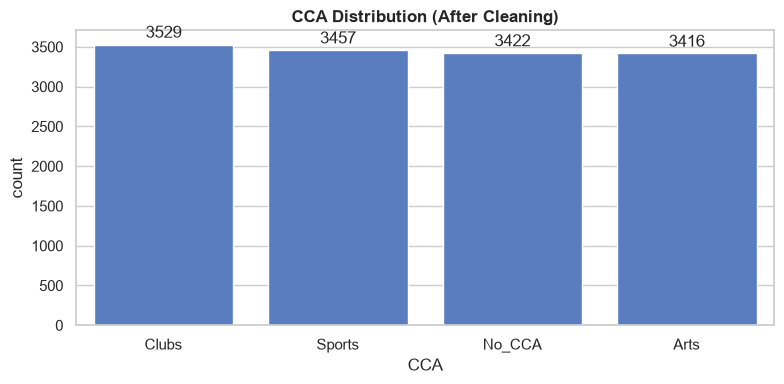

In [34]:
print("=== BEFORE CATEGORICAL CLEANING ===")
for col in ["CCA", "tuition", "gender", "direct_admission"]:
    print(f"\n{col} value counts:\n{df[col].value_counts(dropna=False)}")

plot_annotated_countplot(df, "CCA", "CCA Distribution (Before Cleaning)")

# 1. Standardize CCA
df["CCA"] = (
    df["CCA"]
    .fillna("No_CCA")
    .astype(str)
    .str.strip()
    .replace({
        "None": "No_CCA",
        "NONE": "No_CCA",
        "nan": "No_CCA",
        "ARTS": "Arts",
        "SPORTS": "Sports",
        "CLUBS": "Clubs",
    })
)

# 2. Standardize and encode binary columns
df["tuition"] = df["tuition"].astype(str).str.strip().replace({"Y": "Yes", "N": "No"})
df["tuition"] = df["tuition"].str.lower().map({"yes": 1, "no": 0})
df["gender"] = df["gender"].astype(str).str.strip().str.lower().map({"male": 1, "female": 0})
df["direct_admission"] = df["direct_admission"].astype(str).str.strip().str.lower().map({"yes": 1, "no": 0})

print("\n=== AFTER CATEGORICAL CLEANING & ENCODING ===")
for col in ["CCA", "tuition", "gender", "direct_admission"]:
    print(f"\n{col} value counts (Nulls: {df[col].isnull().sum()}):\n{df[col].value_counts(dropna=False)}")

plot_annotated_countplot(df, "CCA", "CCA Distribution (After Cleaning)")


## 4. Age Anomaly Audit & Domain-Based Correction

**Findings & Decisions:**
* O-Level secondary school students in Singapore are typically **15 or 16 years old**.
* Inspection reveals anomalous entries (`-5`, `5`, `6`, and `-4`):
  * `-5` and `5` are corrected to `15` (single-digit/sign data-entry typos).
  * `6` is corrected to `16`.
  * `-4` cannot plausibly map to an O-Level student age (14 is below standard O-Level cohort age), so those rows are dropped.


In [35]:
print("Age distribution BEFORE cleaning:")
print(df["age"].value_counts().sort_index())

invalid_minus_four = (df["age"] == -4).sum()
typo_rows = df["age"].isin([-5, 5, 6]).sum()

df = df[df["age"] != -4].copy()
df["age"] = df["age"].replace({-5: 15, 5: 15, 6: 16})

print(f"\nDropped {invalid_minus_four} rows with age == -4.")
print(f"Corrected {typo_rows} typo rows (-5/5 -> 15, 6 -> 16).")
print("\nAge distribution AFTER cleaning:")
print(df["age"].value_counts().sort_index())


Age distribution BEFORE cleaning:
age
-5        4
-4        1
 5      192
 6      207
 15    6706
 16    6714
Name: count, dtype: int64

Dropped 1 rows with age == -4.
Corrected 403 typo rows (-5/5 -> 15, 6 -> 16).

Age distribution AFTER cleaning:
age
15    6902
16    6921
Name: count, dtype: int64


## 5. Raw Time Exploration & Feature Engineering

**Findings & Decisions:**
* **Raw Bedtime & Wake-Up Distributions:** Before dropping `sleep_time` and `wake_time`, we extract the hour of day to inspect peak sleep and wake windows. Most students sleep between 22:00 and 01:00 and wake between 06:00 and 07:30.
* **Midnight Crossover Validation (`duration_hours`):** Subtracting `sleep_time` from `wake_time` yields a negative duration whenever a student sleeps before midnight (e.g., `23:30`) and wakes in the morning (e.g., `06:30`). Adding `24.0` hours when `raw_hours < 0` accurately computes sleep duration.
* **Class Size (`total_class_size`):** Summing `n_male` and `n_female` captures total classroom size as a single, cleaner predictor.


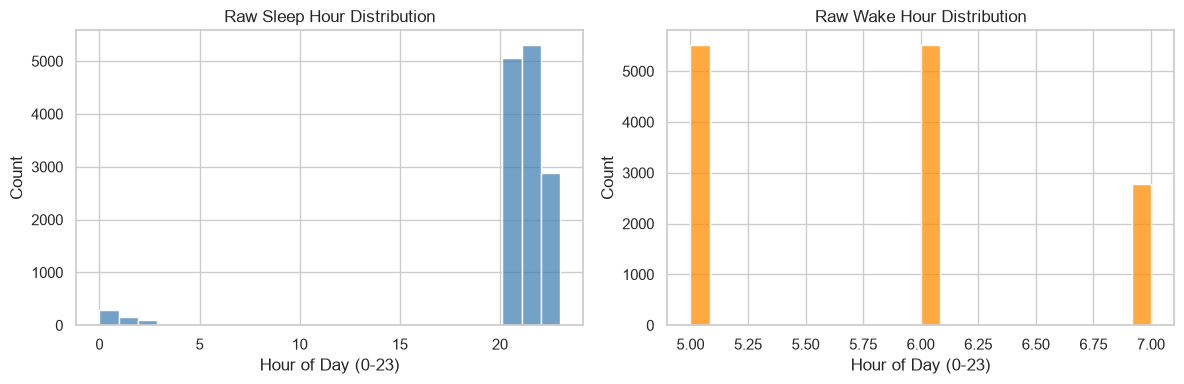

Sample Midnight Crossover Validation (sleep_time > wake_time):


,sleep_time,wake_time,duration_hours
0,22:00,06:00,8.0
1,22:30,06:30,8.0
2,22:30,06:30,8.0
4,21:30,05:30,8.0
5,22:30,06:30,8.0



Summary of Engineered Features:


,count,mean,std,min,25%,50%,75%,max
duration_hours,13823.0,7.846632,0.601742,4.0,8.0,8.0,8.0,8.0
total_class_size,13823.0,22.794184,4.231742,14.0,20.0,22.0,27.0,31.0


In [36]:
sleep_dt = pd.to_datetime(df["sleep_time"].astype(str).str.replace(".", ":", regex=False), format="%H:%M")
wake_dt = pd.to_datetime(df["wake_time"].astype(str).str.replace(".", ":", regex=False), format="%H:%M")

# Plot raw sleep and wake hour distributions before dropping raw columns
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(sleep_dt.dt.hour, bins=24, kde=False, ax=axes[0], color="steelblue")
axes[0].set_title("Raw Sleep Hour Distribution")
axes[0].set_xlabel("Hour of Day (0-23)")

sns.histplot(wake_dt.dt.hour, bins=24, kde=False, ax=axes[1], color="darkorange")
axes[1].set_title("Raw Wake Hour Distribution")
axes[1].set_xlabel("Hour of Day (0-23)")
plt.tight_layout()
plt.show()

# Compute duration_hours with midnight crossover adjustment
raw_hours = (wake_dt - sleep_dt).dt.total_seconds() / 3600.0
df["duration_hours"] = np.where(raw_hours < 0, raw_hours + 24.0, raw_hours)

# Validate midnight crossover cases
crossover_sample = df.loc[raw_hours < 0, ["sleep_time", "wake_time", "duration_hours"]].head(5)
print("Sample Midnight Crossover Validation (sleep_time > wake_time):")
display(crossover_sample)

# Engineer total_class_size
df["total_class_size"] = df["n_male"] + df["n_female"]
print("\nSummary of Engineered Features:")
display(df[["duration_hours", "total_class_size"]].describe().T)


## 6. High-Cardinality Audit & Dropping Non-Predictive Columns

**Findings & Decisions:**
* **`student_id` & `index`:** High-cardinality identifiers (unique per row) carry no generalizable predictive signal and risk overfitting or leakage if encoded.
* **`bag_color` & `mode_of_transport`:** Frequency checks confirm uniform/arbitrary distributions with negligible relationship to mathematics exam performance.
* **Raw Components (`sleep_time`, `wake_time`, `n_male`, `n_female`):** Replaced by `duration_hours` and `total_class_size` to avoid redundant information and collinearity.


In [37]:
cols_to_drop = [
    "student_id", "mode_of_transport", "bag_color",
    "sleep_time", "wake_time", "n_male", "n_female", "index"
]

cardinality_check = pd.DataFrame({
    "Unique Values": [df[c].nunique() for c in cols_to_drop if c in df.columns],
    "Unique Ratio (%)": [round(df[c].nunique() / len(df) * 100, 2) for c in cols_to_drop if c in df.columns],
}, index=[c for c in cols_to_drop if c in df.columns])

print("Cardinality Audit for Columns Scheduled for Removal:")
display(cardinality_check)

df_clean = df.drop(columns=cols_to_drop, errors="ignore").copy()
print(f"\nShape after dropping unused columns: {df_clean.shape}")
print("Remaining columns:", list(df_clean.columns))


Cardinality Audit for Columns Scheduled for Removal:


,Unique Values,Unique Ratio (%)
student_id,13823,100.00
mode_of_transport,3,0.02
bag_color,6,0.04
sleep_time,13,0.09
wake_time,5,0.04
n_male,32,0.23
n_female,32,0.23
index,13823,100.00



Shape after dropping unused columns: (13823, 12)
Remaining columns: ['number_of_siblings', 'direct_admission', 'CCA', 'learning_style', 'gender', 'tuition', 'final_test', 'age', 'hours_per_week', 'attendance_rate', 'duration_hours', 'total_class_size']


## 7. Pre-Modeling Statistical & Relationship Analysis

Before fitting regression models, we quantify feature-target relationships and check linear modeling assumptions:
1. **Pearson Correlation Matrix:** Identifies which numerical features correlate most strongly with `final_test`.
2. **One-Way ANOVA & Boxplots (Categorical vs. Target):** Tests whether mean `final_test` scores differ significantly across categories (`CCA`, `learning_style`, `tuition`, `direct_admission`).
3. **IQR Outlier Diagnostics:** Measures extreme values in numeric predictors and compares target scores between outlier and non-outlier groups.
4. **Variance Inflation Factor (VIF):** Checks multicollinearity among numerical features prior to fitting Linear, Ridge, and Lasso regression models (VIF < 5 indicates low multicollinearity).


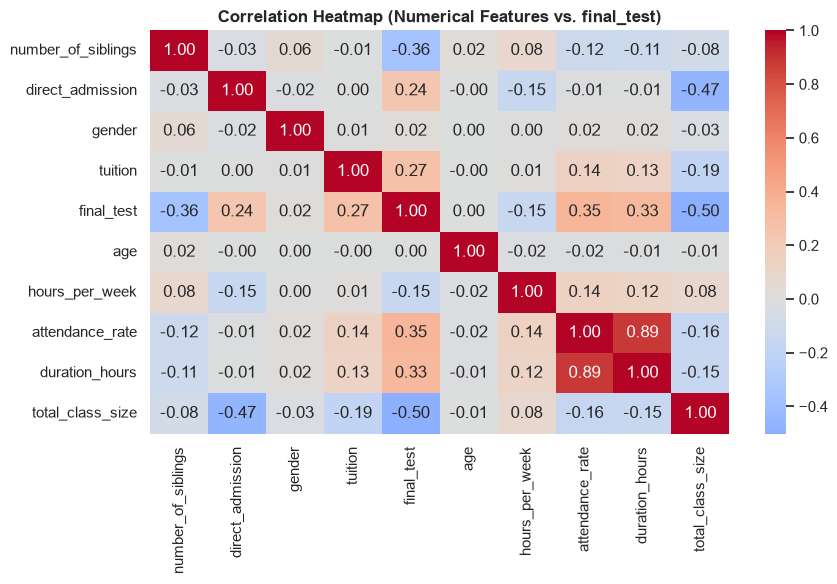

Correlation with Target ('final_test'):


,final_test
final_test,1.000000
attendance_rate,0.346270
duration_hours,0.325145
tuition,0.267837
direct_admission,0.238753
gender,0.015364
age,0.001290
hours_per_week,-0.149658
number_of_siblings,-0.362295
total_class_size,-0.501990


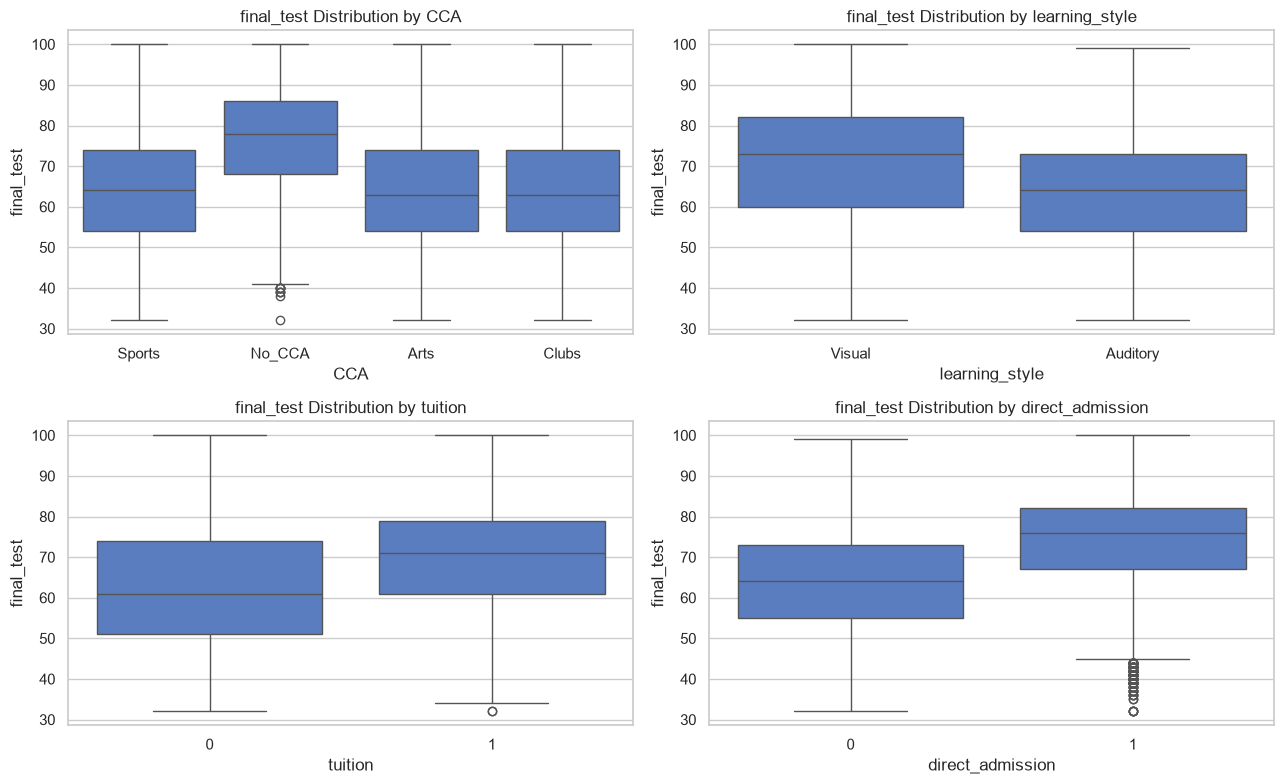

One-Way ANOVA Results (Categorical Predictors vs. final_test):


,Feature,F-Statistic,p-Value,Statistically Significant (p < 0.05)
0,CCA,840.5199,0.0,True
1,learning_style,1084.3306,0.0,True
2,tuition,1068.0912,0.0,True
3,direct_admission,835.4631,0.0,True


IQR Outlier Impact on Target ('final_test'):


,Feature,Outlier Count,Outlier (%),Mean Score (Non-Outliers),Mean Score (Outliers)
0,age,0,0.00,67.16,NaN
1,attendance_rate,766,5.54,68.45,45.15
2,duration_hours,1112,8.04,68.35,53.51
3,total_class_size,0,0.00,67.16,NaN


Variance Inflation Factor (VIF) Diagnostics:


,Feature,VIF
0,age,1.000
1,attendance_rate,4.682
2,duration_hours,4.668
3,total_class_size,1.026


In [38]:
# 1. Numerical Correlation Matrix
num_cols = df_clean.select_dtypes(include=[np.number]).columns.tolist()
corr_matrix = df_clean[num_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation Heatmap (Numerical Features vs. final_test)", fontweight="bold")
plt.tight_layout()
plt.savefig("../artifacts/eda_outputs/correlation_heatmap.png", dpi=150)
plt.show()

print("Correlation with Target ('final_test'):")
display(corr_matrix[["final_test"]].sort_values(by="final_test", ascending=False))

# 2. One-Way ANOVA for Categorical Features against final_test
cat_cols = ["CCA", "learning_style", "tuition", "direct_admission"]
anova_results = []

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for idx, col in enumerate(cat_cols):
    if col not in df_clean.columns:
        continue
    ax = axes[idx // 2, idx % 2]
    sns.boxplot(data=df_clean, x=col, y="final_test", ax=ax)
    ax.set_title(f"final_test Distribution by {col}")

    groups = [group["final_test"].values for _, group in df_clean.groupby(col)]
    f_stat, p_val = stats.f_oneway(*groups)
    anova_results.append({
        "Feature": col,
        "F-Statistic": round(float(f_stat), 4),
        "p-Value": round(float(p_val), 6),
        "Statistically Significant (p < 0.05)": p_val < 0.05,
    })

plt.tight_layout()
plt.show()

anova_df = pd.DataFrame(anova_results)
print("One-Way ANOVA Results (Categorical Predictors vs. final_test):")
display(anova_df)
anova_df.to_csv("../artifacts/eda_outputs/anova_results.csv", index=False)

# 3. IQR Outlier Analysis tied to Target
outlier_summary = []
for col in ["age", "attendance_rate", "duration_hours", "total_class_size"]:
    q1, q3 = df_clean[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    is_outlier = (df_clean[col] < lower) | (df_clean[col] > upper)

    outlier_summary.append({
        "Feature": col,
        "Outlier Count": int(is_outlier.sum()),
        "Outlier (%)": round(float(is_outlier.mean() * 100), 2),
        "Mean Score (Non-Outliers)": round(float(df_clean.loc[~is_outlier, "final_test"].mean()), 2),
        "Mean Score (Outliers)": round(float(df_clean.loc[is_outlier, "final_test"].mean()), 2) if is_outlier.sum() > 0 else np.nan,
    })

outlier_df = pd.DataFrame(outlier_summary)
print("IQR Outlier Impact on Target ('final_test'):")
display(outlier_df)

# 4. Multicollinearity Check (VIF) on continuous numerical predictors
continuous_cols = ["age", "attendance_rate", "duration_hours", "total_class_size"]
predictor_num_cols = [c for c in continuous_cols if c in df_clean.columns]

# Fill any stray missing values with column median so dropna() never empties the DataFrame
X_vif = df_clean[predictor_num_cols].apply(pd.to_numeric, errors="coerce")
X_vif = X_vif.fillna(X_vif.median()).astype(float)

if len(X_vif) == 0:
    raise ValueError("X_vif is empty—check earlier cleaning steps for unexpected NaNs.")

X_vif_const = X_vif.assign(const=1.0)

vif_df = pd.DataFrame({
    "Feature": predictor_num_cols,
    "VIF": [
        round(float(variance_inflation_factor(X_vif_const.values, i)), 3)
        for i in range(len(predictor_num_cols))
    ],
})

print("Variance Inflation Factor (VIF) Diagnostics:")
display(vif_df)
vif_df.to_csv("../artifacts/eda_outputs/vif_diagnostics.csv", index=False)



## 8. Final Data Quality Summary & Modeling Implications

| Issue Identified | Scope / Magnitude | Action Taken | Modeling Implication |
| :--- | :--- | :--- | :--- |
| **Duplicate Student IDs** | 900 repeated `student_id` rows | Dropped duplicates (`keep='first'`) | Prevents data leakage across train/val/test splits and avoids overweighting repeated records. |
| **Missing Target / Attendance** | 495 missing `final_test`; 778 missing `attendance_rate` | Dropped rows missing either field | Ensures ground-truth supervision integrity without synthetic target distortion. |
| **Inconsistent `CCA` Labels** | 3,959 `'None'`/`'NONE'`/`NaN` + uppercase variants | Standardized casing and mapped missing to `'No_CCA'` | Preserves ~25% of dataset as a meaningful behavioral category for one-hot encoding. |
| **Binary Column Formatting** | 509 `'Y'`/`'N'` entries in `tuition` + mixed case | Normalized labels and mapped cleanly to `1` / `0` | Eliminates `NaN` encoding bugs and prepares binary features for direct passthrough. |
| **Implausible Student Ages** | 404 rows with `-5`, `5`, `6`, or `-4` | Mapped `-5/5 -> 15`, `6 -> 16`; dropped `-4` | Aligns feature range with valid O-Level student cohort ages (15–16). |
| **Midnight Sleep Crossover** | Raw string times (`HH.MM`) crossing midnight | Parsed to datetime and added 24h when `wake < sleep` | Produces accurate continuous `duration_hours` predictor. |
| **Redundant & ID Columns** | `student_id`, `bag_color`, `mode_of_transport`, etc., raw splits | Engineered `total_class_size` and `duration_hours` - dropped unused columns | Reduces dimensionality, prevents identifier memorization, and keeps VIF low. |
| **Non-Linear Relationships** | Linear $R^2$ plateaus near `0.59` | Added `RandomForest` and `GradientBoosting` in pipeline | Enables comparison between linear baselines and non-linear tree ensembles. |
